# Analysis of Post-Predictives

This aim of this notebook is to gain stronger intuitions regarding our model selection results. That is, *why* is CO the best model when fitting adaptation?

One idea I wish to test is how the simulated adaptation measures from each model compare to the actual adaptation measures. In other words, to correlate the two and visualize them through a scatterplot. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import scipy.optimize
from scipy.optimize import minimize
from scipy.stats import norm
from scipy.special import logsumexp
import warnings
from scipy.optimize import curve_fit
from scipy.optimize import approx_fprime
import scipy.stats as stats
from pybads import BADS

from matplotlib.colors import LinearSegmentedColormap

# TEMP
warnings.simplefilter("ignore", category=FutureWarning)

from src.src import *

# Set some defaults
plt.rc("axes.spines", top=False, right=False)
plt.rcParams["mathtext.default"] = "regular"
sns.set_theme("paper", font_scale=1.3)
sns.set_style("ticks")

%config InlineBackend.figure_format = "retina"

---
## Helper functions

In [2]:
# Helper functions
def converter(input_str):
    return np.fromstring(input_str[1:-1], sep=' ')

---
## Import data

In addition to empirical adaptation metrics from each participant we want posterior predictives from at least CO and PIECE models. It may be easier to simulate posterior predictives within this notebook (see "analyze-models.ipynb"), as opposed to importing them. Due to the stochastic nature of the simulations, we want to see how things change upon repeated simulations. 


In [3]:
# Read in data 
df_behav = pd.read_csv("combined-data.csv")
fits_adapt = pd.read_csv("model-fits/fits_adapt.csv", converters={"params": converter})


In [4]:
# Choose a sample subject
subj_id = 1
sample_subj = df_behav.loc[(df_behav["SN"] == subj_id) & (df_behav["session"] == "adapt"), :].reset_index(drop=True)
sigma_motor = sample_subj.loc[0, "sigma_motor_adapt"]

# Pull out best-fit adaptation params for chosen subject:
vco_mles = fits_adapt.loc[fits_adapt["model"] == "vco", ["C", "B", "sigma_v", "b"]]
co_mles = fits_adapt.loc[fits_adapt["model"] == "co", ["C", "B", "sigma_comb", "b"]]
piece_mles = fits_adapt.loc[fits_adapt["model"] == "piece", ["alpha", "beta", "sigma_p", "sigma_pert", "b"]]


In [5]:
# Simulate adaptation with best-fit parameters
# VCO model
xhat_vco = vco_simulate_adapt(
    df=sample_subj,
    C=vco_mles["C"].values[0], 
    B=vco_mles["B"].values[0],
    sigma_v=vco_mles["sigma_v"].values[0],
    b=vco_mles["b"].values[0],
)
# Need to match number of simulated adapt measures without importing last bsl trial
xhat_vco = np.insert(xhat_vco, 0, np.random.normal(loc=vco_mles["b"].values[0], scale=sigma_motor))  
adapt_vco = xhat_vco[2::2] - xhat_vco[0:-1:2]


# CO model
xhat_co = co_simulate_adapt(
    df=sample_subj,
    C=co_mles["C"].values[0], 
    B=co_mles["B"].values[0],
    sigma_comb=co_mles["sigma_comb"].values[0],
    b=co_mles["b"].values[0],
    sigma_plan=3
)
# Need to match number of simulated adapt measures without importing last bsl trial
xhat_co = np.insert(xhat_co, 0, np.random.normal(loc=co_mles["b"].values[0], scale=sigma_motor))  
adapt_co = xhat_co[2::2] - xhat_co[0:-1:2]


# PIECE model
xhat_piece = piece_simulate_adapt(
    df=sample_subj,
    alpha=piece_mles["alpha"].values[0], 
    beta=piece_mles["beta"].values[0],
    sigma_p=piece_mles["sigma_p"].values[0],
    sigma_pert=piece_mles["sigma_pert"].values[0],
    b=piece_mles["b"].values[0],
)
# Need to match number of simulated adapt measures without importing last bsl trial
xhat_piece = np.insert(xhat_piece, 0, np.random.normal(loc=piece_mles["b"].values[0], scale=sigma_motor))  
adapt_piece = xhat_piece[2::2] - xhat_piece[0:-1:2]

In [6]:
# Find perturbation trials in data frame
pert_indices = np.flatnonzero(sample_subj["pert_trial"])

# Trim subject data frame to only adaptation trials
df_trimmed = sample_subj.loc[pert_indices, :]
SN = df_trimmed.loc[:, "SN"]
rotation = df_trimmed.loc[:, "delta_xv"]

# Create variable that tracks whether rotation is small or large
saturated_zone = np.abs(df_trimmed["delta_xv"]) >= 10

# Create data frame with all perturbation trials
df_plot = pd.DataFrame({
    "delta_xv" : df_trimmed.loc[:, "delta_xv"],
    "adaptation" : df_trimmed.loc[:, "adaptation"],
    "x_f" : df_trimmed.loc[:, "x_f_clean"],
    "xhat_vco" : xhat_vco[1::2],
    "adapt_vco" : adapt_vco,
    "xhat_co" : xhat_co[1::2],
    "adapt_co" : adapt_co,
    "xhat_piece" : xhat_piece[1::2], 
    "adapt_piece" : adapt_piece, 
    "rotation" : rotation,
    "saturated_zone" : saturated_zone,
    "SN" : SN
})


# Create a long dataframe
df_vco = pd.DataFrame({
    "delta_xv" : np.tile(df_trimmed.loc[:, "delta_xv"], 2),
    "adaptation" : np.concatenate((df_trimmed.loc[:, "adaptation"], adapt_vco)),
    "rotation" : np.tile(rotation, 2),
    "SN" : np.tile(SN, 2),
    "data_source" : np.concatenate((np.repeat("real", len(rotation)), np.repeat("vco", len(rotation)))),
})

df_co = pd.DataFrame({
    "delta_xv" : np.tile(df_trimmed.loc[:, "delta_xv"], 2),
    "adaptation" : np.concatenate((df_trimmed.loc[:, "adaptation"], adapt_co)),
    "rotation" : np.tile(rotation, 2),
    "SN" : np.tile(SN, 2),
    "data_source" : np.concatenate((np.repeat("real", len(rotation)), np.repeat("co", len(rotation)))),
})

df_piece = pd.DataFrame({
    "delta_xv" : np.tile(df_trimmed.loc[:, "delta_xv"], 2),
    "adaptation" : np.concatenate((df_trimmed.loc[:, "adaptation"], adapt_piece)),
    "rotation" : np.tile(rotation, 2),
    "SN" : np.tile(SN, 2),
    "data_source" : np.concatenate((np.repeat("real", len(rotation)), np.repeat("piece", len(rotation)))),
})

24.391160134652882 26.8671569995731 21.658204866869866
18.019782043574107 19.457979148202142 19.399640278628553 19.05274877329859


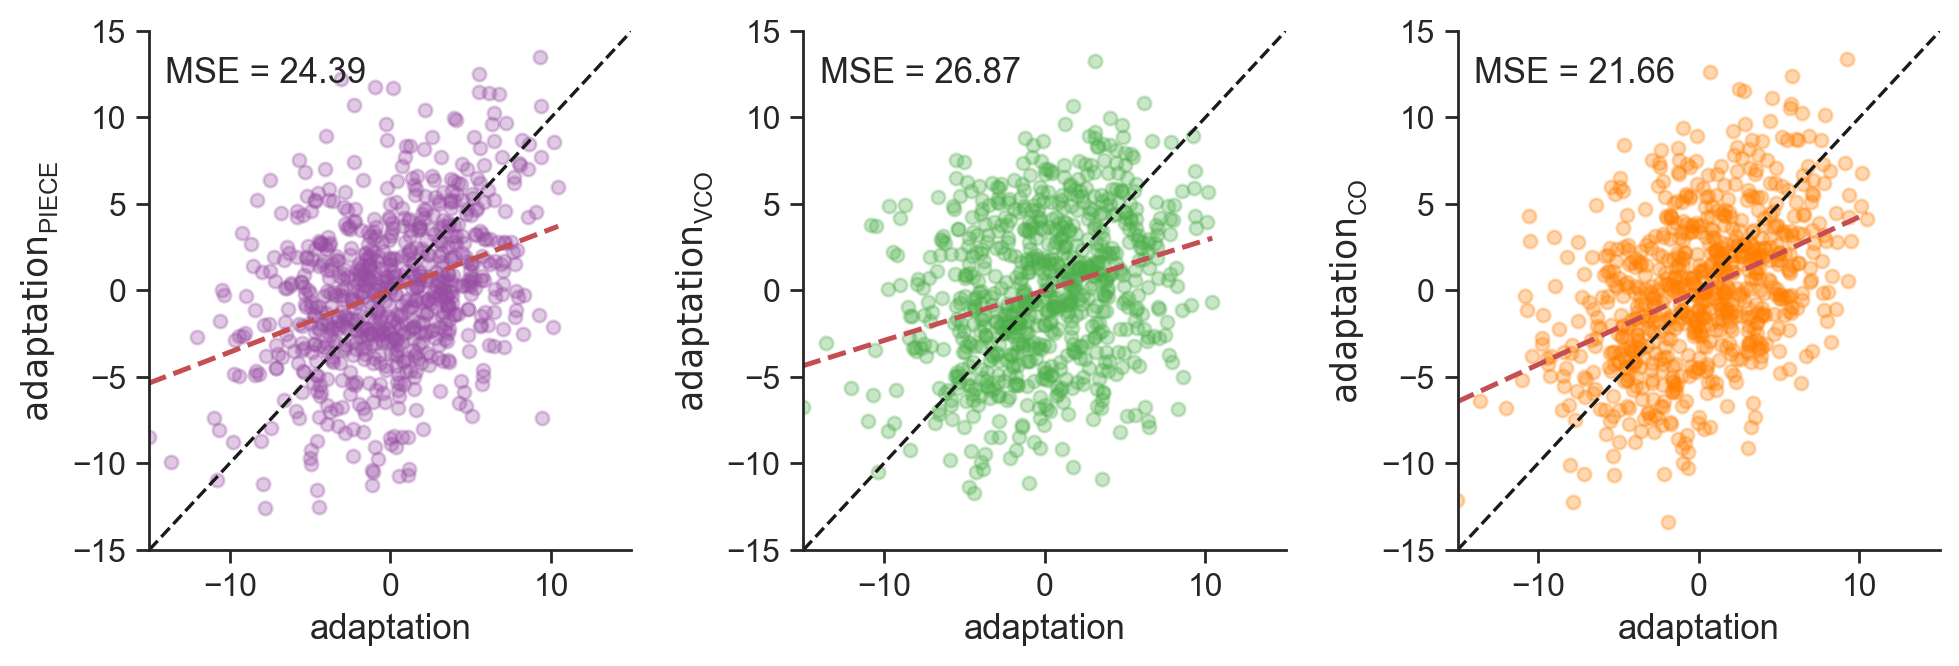

In [9]:
# Assign colors to models
piece_color = '#984ea3'  # purple
vco_color = '#4daf4a'  # green
co_color = '#ff7f00'  # orange

sse_piece = ((df_plot["adaptation"] - df_plot["adapt_piece"])**2).sum()
sse_vco = ((df_plot["adaptation"] - df_plot["adapt_vco"])**2).sum()
sse_co = ((df_plot["adaptation"] - df_plot["adapt_co"])**2).sum()
num_obs = df_plot["adaptation"].nunique()

mse_piece = sse_piece / num_obs
mse_vco = sse_vco / num_obs
mse_co = sse_co / num_obs
print(mse_piece, mse_vco, mse_co)

# Plotting scatterplots of simulated adaptation against real data. There are some 
# outliers in real data, but it's okay because scatter is smart enough to skip over
# data pairings where one or more values is missing. 
low, high = -15, 15
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(10, 3.5))
sns.despine()

sns.regplot(data=df_plot, x="adaptation", y="adapt_piece", ci=None, ax=ax1, scatter_kws={"alpha":0.3, "color":piece_color}, 
            line_kws={"linestyle":"--", "color":"r"})
ax1.plot([low, high], [low, high], linestyle="--", color="k")
ax1.set(xlim=[low, high], ylim=[low, high], ylabel=r"$\text{adaptation}_{PIECE}$")
ax1.text(-14, 12, f"MSE = {mse_piece:.2f}")

sns.regplot(data=df_plot, x="adaptation", y="adapt_vco", ci=None, ax=ax2, scatter_kws={"alpha":0.3, "color":vco_color}, 
            line_kws={"linestyle":"--", "color":"r"})
ax2.plot([-15, 15], [-15, 15], linestyle="--", color="k")
ax2.set(xlim=[low, high], ylim=[low, high], ylabel=r"$\text{adaptation}_{VCO}$")
ax2.text(-14, 12, f"MSE = {mse_vco:.2f}")

sns.regplot(data=df_plot, x="adaptation", y="adapt_co", ci=None, ax=ax3, scatter_kws={"alpha":0.3, "color":co_color}, 
            line_kws={"linestyle":"--", "color":"r"})
ax3.plot([-15, 15], [-15, 15], linestyle="--", color="k")
ax3.set(xlim=[low, high], ylim=[low, high], ylabel=r"$\text{adaptation}_{CO}$")
ax3.text(-14, 12, f"MSE = {mse_co:.2f}")
plt.tight_layout()
plt.savefig("../figs/scatterplots-postpreds.pdf", dpi=300)

var_behav = df_plot["adaptation"].var()
var_piece = df_plot["adapt_piece"].var()
var_vco = df_plot["adapt_vco"].var()
var_co = df_plot["adapt_co"].var()
print(var_behav, var_piece, var_vco, var_co)

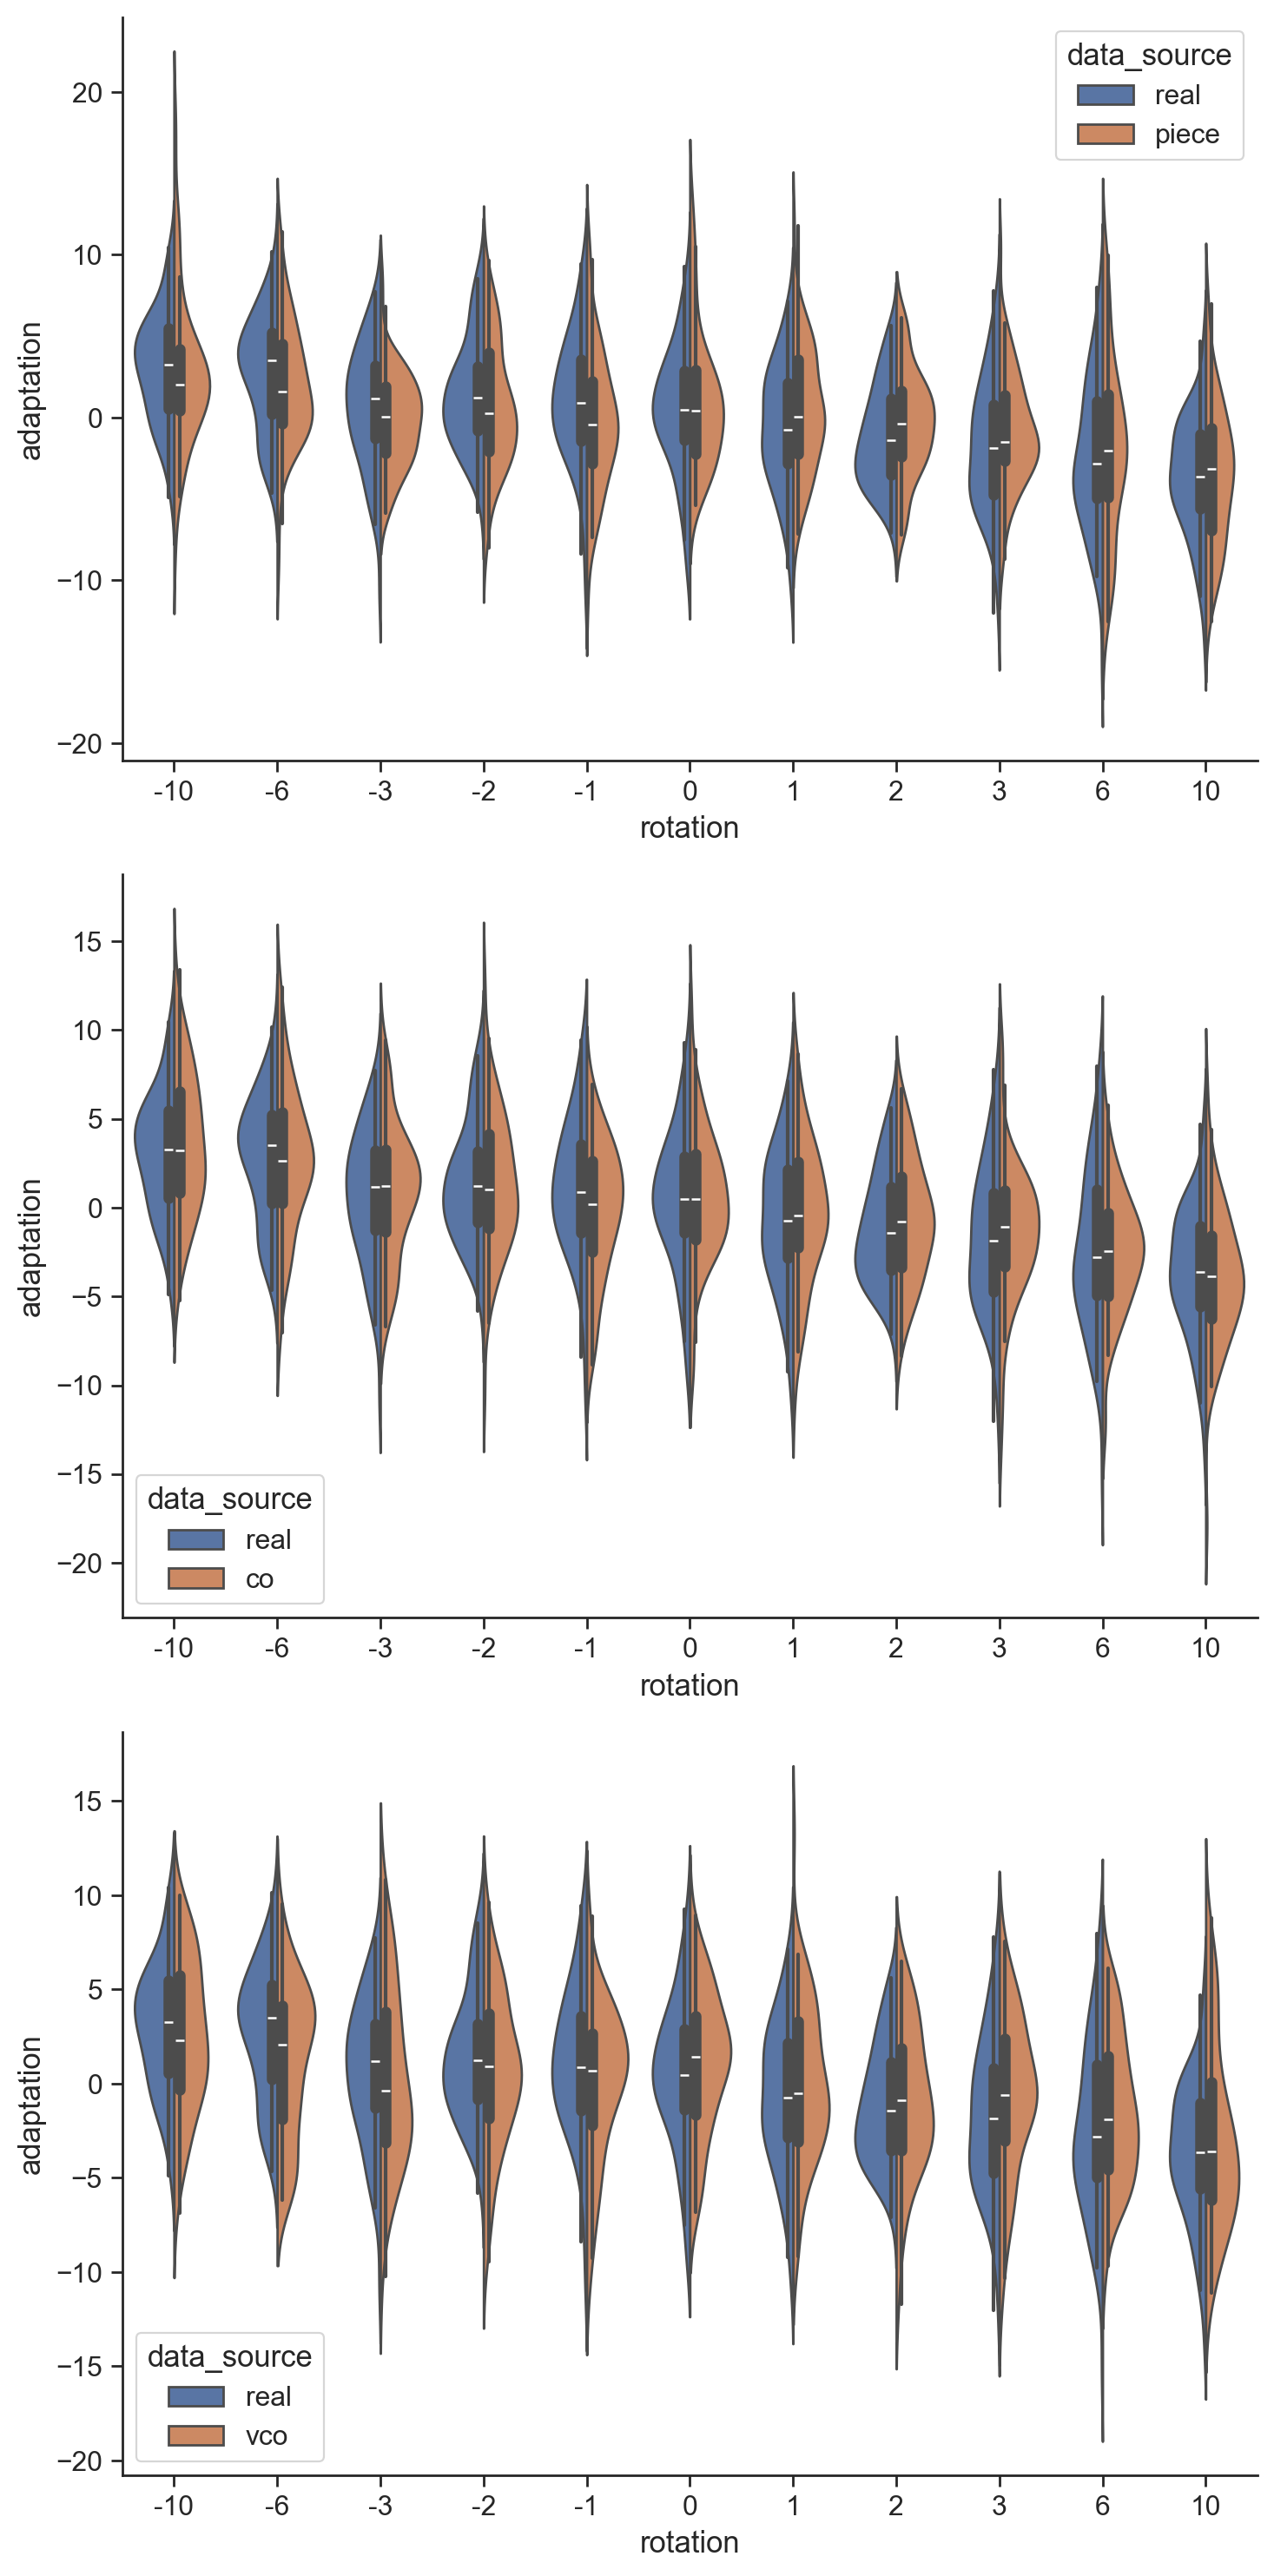

In [8]:
# Plot comparisons of response distributions at each pert level
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(7.5, 15))
sns.despine()
sns.violinplot(data=df_piece, x="rotation", y="adaptation", hue="data_source", 
                alpha=1, ax=ax1, split=True)
sns.violinplot(data=df_co, x="rotation", y="adaptation", hue="data_source", 
                alpha=1, ax=ax2, split=True)
sns.violinplot(data=df_vco, x="rotation", y="adaptation", hue="data_source", 
                alpha=1, ax=ax3, split=True)
plt.tight_layout()
